Second version of a script to process incredibly grainy image data. Changed Randomized Hough Transform to RANSAC, which provided a much better fit to the data.

In [1]:
import skimage as ski
import os 
import numpy as np
from PIL import Image
from scipy.fft import fft2, fftshift
from scipy.ndimage import median_filter

from skimage.restoration import ( 
    denoise_tv_chambolle,
    denoise_bilateral,
    denoise_wavelet,
    estimate_sigma,
)

import matplotlib.pyplot as plt

import numpy as np

from skimage.transform import hough_line, hough_line_peaks
from skimage.feature import canny
from skimage.draw import line as draw_line
from skimage import data

import matplotlib.pyplot as plt
from matplotlib import cm


In [4]:
# plan
# -> Crop more closely
# -> Fit a 5 degree polynomial for horizontal. 


In [2]:
# Utility

def to_u8(img):
    return ((img - img.min()) / (img.max() - img.min()) * 255).astype(np.uint8)

def get_file(num, prefix = 'imgs2/raw', suffix = ".tif"):

    filename = os.path.join('.', prefix, f'{num:0>5}{suffix}')
    img=ski.io.imread(filename)
    return img

def get_avg_img(num, k=2):
    img_sum = get_file(max(1, num-k)).astype(np.uint16)
    #disp(img_sum)
    for i in range(max(1, num-k+1), min(num+k+1, 609)):
        img_sum += get_file(i).astype(np.uint16)
        #disp(to_u8(img_sum))

    return to_u8(img_sum)

def disp(img):
    display( Image.fromarray(np.uint8(img)).convert('RGB'))

def disp_float(img):
    img = to_u8(img)
    display( Image.fromarray(np.uint8(img)).convert('RGB'))

def disp_bool(img):
    display( Image.fromarray(np.bool(img)).convert('RGB'))

def bi_dn(img):
    return denoise_bilateral(img, win_size = 5, sigma_spatial=1)

In [6]:
# Initialization
img1 = get_avg_img(6)
imgs = [get_avg_img(i, 3).astype(np.uint16) for i in range(30,600, 30)]

In [7]:
#disp(imgs[0][395:520, 270:550])

"""Return left_v, right_v, top_h, bot_h
In the interest of my sanity, we maintain a uniform left corner
"""

left_x = 200
left_y = 390
right_offset = 280
bot_offset = 80
right_x = 550

def crop(img):
    return [img[left_y:520, left_x:320], img[left_y:520, (left_x + right_offset):right_x], img[left_y:left_y+50, left_x:right_x], img[left_y+bot_offset:520, left_x:right_x]]

def offset_equation_top_left(func):
    def offset(x):
        return func(x-left_x)+left_y
    return offset

def offset_equation_top_right(func):
    def offset(x):
        return func(x-(left_x + right_offset))+left_y
    return offset

def offset_equation_bot_left(func):
    def offset(x):
        return func(x-left_x)+left_y+bot_offset
    return offset

570


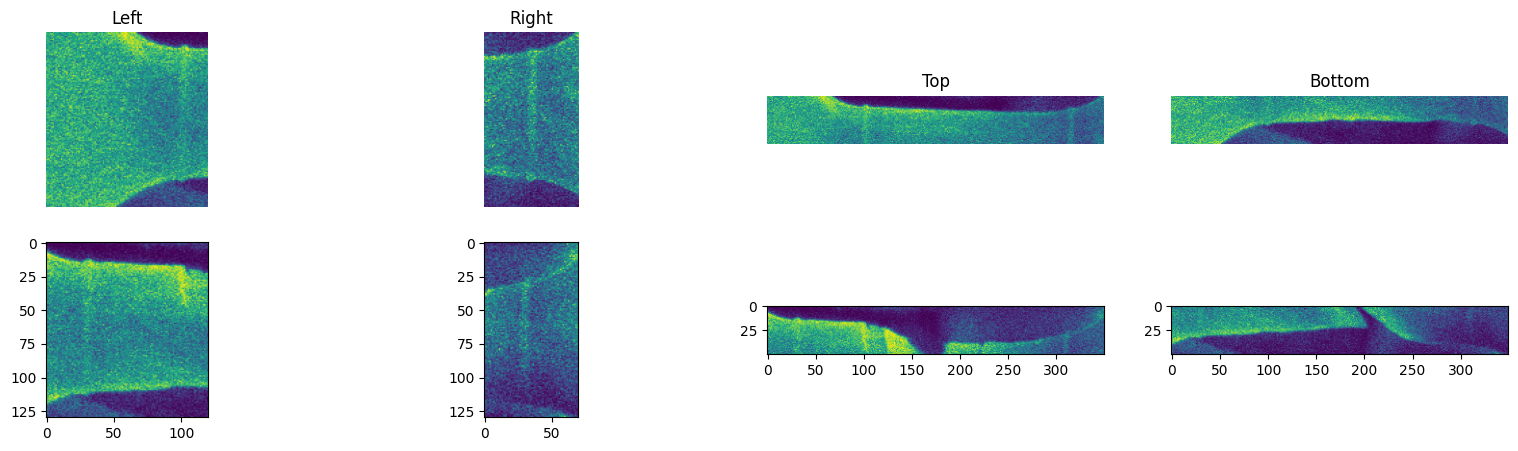

In [8]:
fig, ax = plt.subplots(2, 4, figsize=(20, 5))

img1_crops = crop(imgs[0])
img420_crops = crop(imgs[len(imgs)-1])

print(30 * len(imgs))

ax[0][0].imshow(img1_crops[0])
ax[0][0].set_axis_off()
ax[0][0].set_title('Left')
ax[0][1].imshow(img1_crops[1])
ax[0][1].set_axis_off()
ax[0][1].set_title('Right')
ax[0][2].imshow(img1_crops[2])
ax[0][2].set_axis_off()
ax[0][2].set_title('Top')
ax[0][3].imshow(img1_crops[3])
ax[0][3].set_axis_off()
ax[0][3].set_title('Bottom')

ax[1][0].imshow(img420_crops[0])
ax[1][1].imshow(img420_crops[1])
ax[1][2].imshow(img420_crops[2])
ax[1][3].imshow(img420_crops[3])

In [9]:
def average_out_lines(img, thresh = 10):
    tested_angles = np.linspace(0, np.pi / 64, 360, endpoint=False)
    h, theta, d = hough_line(img, theta=tested_angles)

    existing_lines = []

    for _, angle, dist in zip(*hough_line_peaks(h, theta, d, num_peaks=15)):
        (x0, y0) = dist * np.array([np.cos(angle), np.sin(angle)])
        averaged= False

        for line in existing_lines:
            if (abs(line[0]-x0) < thresh):
                line[0] = (line[3] * line[0] + x0)/(line[3]+1)
                line[1] = line[1] + y0
                line[2] = line[2] + np.tan(angle + np.pi / 2)
                line[3]+=1
                averaged = True
                break
        if not averaged:
            existing_lines.insert(0, [x0, y0, np.tan(angle + np.pi / 2), 1])

    for line in existing_lines:
        line[1]/=line[3]
        line[2]/=line[3]

    existing_lines.sort(key=(lambda a : a[3]), reverse=True)

    return existing_lines[:1]

def add_figures(can_img, img, ax, name='Original image'):
    tested_angles = np.linspace(0, np.pi / 64, 360, endpoint=False)
    h, theta, d = hough_line(can_img, theta=tested_angles)

    ax[0].imshow(can_img, cmap=cm.gray)
    ax[0].set_title(name)
    ax[0].set_axis_off()

    ax[1].imshow(can_img, cmap=cm.gray)
    #ax[1].set_ylim((can_img.shape[0], 0))
    ax[1].set_axis_off()
    ax[1].set_title('Detected lines')

    ax[2].imshow(img, cmap=cm.gray)
    ax[2].set_axis_off()

    for _, angle, dist in zip(*hough_line_peaks(h, theta, d, num_peaks=15)):
        (x0, y0) = dist * np.array([np.cos(angle), np.sin(angle)])
        ax[1].axline((x0, y0), slope=np.tan(angle + np.pi / 2))
        ax[2].axline((x0, y0), slope=np.tan(angle + np.pi / 2))
        
    for x0, y0, angle, _ in average_out_lines(can_img, 15):
        ax[1].axline((x0, y0), slope=angle, color="red")
        ax[2].axline((x0, y0), slope=angle, color="red")


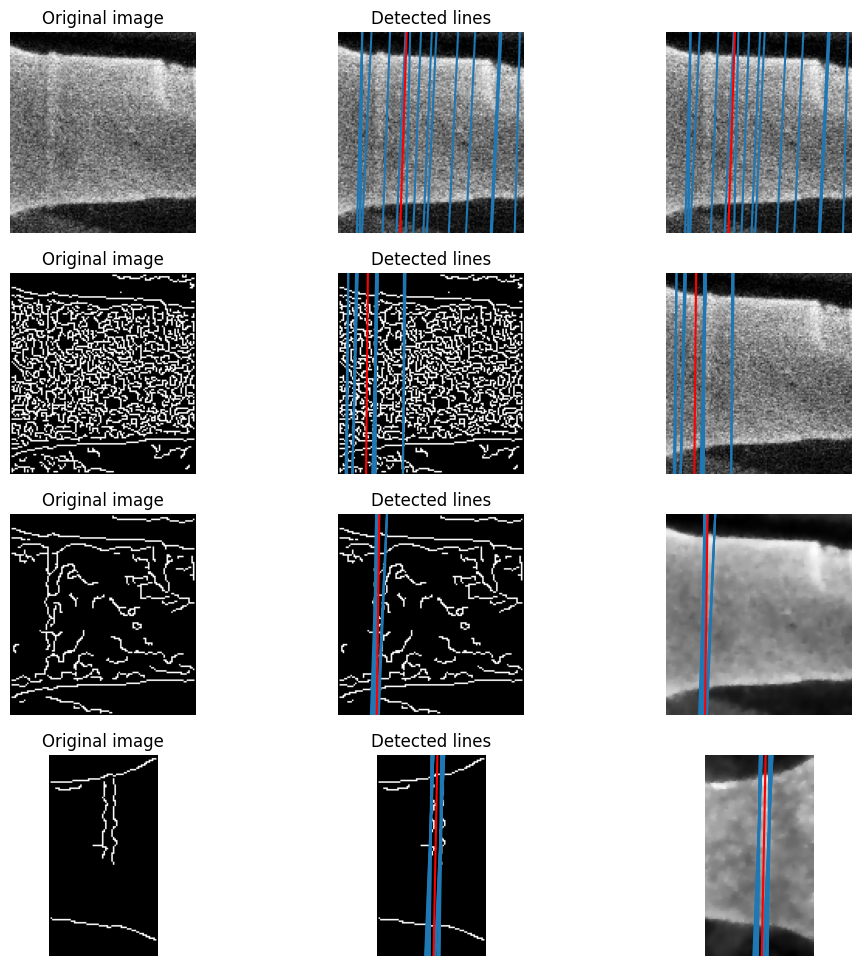

In [10]:
fig, axes = plt.subplots(4, 3, figsize=(12, 12))

img_left=(crop(get_avg_img(600, 3)))[0]
img_right=(crop(get_avg_img(15, 3)))[1]

def add_figures(can_img, img, ax, name='Original image'):
    tested_angles = np.linspace(0, np.pi / 64, 360, endpoint=False)
    h, theta, d = hough_line(can_img, theta=tested_angles)

    ax[0].imshow(can_img, cmap=cm.gray)
    ax[0].set_title(name)
    ax[0].set_axis_off()

    ax[1].imshow(can_img, cmap=cm.gray)
    #ax[1].set_ylim((can_img.shape[0], 0))
    ax[1].set_axis_off()
    ax[1].set_title('Detected lines')

    for _, angle, dist in zip(*hough_line_peaks(h, theta, d, num_peaks=15)):
        (x0, y0) = dist * np.array([np.cos(angle), np.sin(angle)])
        ax[1].axline((x0, y0), slope=np.tan(angle + np.pi / 2))


    ax[2].imshow(img, cmap=cm.gray)
    ax[2].set_axis_off()
    for _, angle, dist in zip(*hough_line_peaks(h, theta, d, num_peaks=15)):
            (x0, y0) = dist * np.array([np.cos(angle), np.sin(angle)])
            ax[2].axline((x0, y0), slope=np.tan(angle + np.pi / 2))
            #print(x0, y0, np.tan(angle + np.pi / 2))

    for x0, y0, angle, _ in average_out_lines(can_img, 15):
            ax[1].axline((x0, y0), slope=angle, color="red")
            ax[2].axline((x0, y0), slope=angle, color="red")
add_figures(img_left, img_left, axes[0])
add_figures(ski.feature.canny(img_left), img_left, axes[1])
add_figures(ski.feature.canny(denoise_tv_chambolle(img_left, weight=0.07)), denoise_tv_chambolle(img_left), axes[2])
add_figures(ski.feature.canny(denoise_tv_chambolle(img_right)), denoise_tv_chambolle(img_right), axes[3])


In [11]:
#RANSAC

def PolyCoefficients(x, coeffs):
    """ Returns a polynomial for ``x`` values for the ``coeffs`` provided.

    The coefficients must be in ascending order (``x**0`` to ``x**o``).
    """
    #print(x)
    o = len(coeffs)
    y = 0
    for i in range(o):
        y += coeffs[i]*x**i

    #y = np.clip(y, 0, 40)    
    return y

def find_inliers(points, coeff, max_error = 1):
    points = np.array(points)
    x = points[:, 0]
    y = points[:, 1]

    y_pred = PolyCoefficients(x, coeff)

    diff = np.absolute(y - y_pred)

    inlier = diff < max_error

    #print(points.shape)

    return points[np.argwhere(inlier)]

def RANSAC(points, min_samples, max_it, max_error, data_threshold):
    #instead of minimizing error, we're probobly going to try and maximize points.
    it = 0
    best_coeff = ()
    best_score = 0

    sane = generate_sanity(350, 60)

    points = np.array(points)
    

    while it < max_it:
        idx = np.random.choice(points.shape[0], min_samples, replace=False)
        sample_points = points[idx]

        x_sample = sample_points[:, 0]
        y_sample = sample_points[:, 1]

        if len(np.unique(x_sample)) < min_samples:
            continue

        import warnings
        warnings.simplefilter('ignore', np.exceptions.RankWarning)
        coeffs = np.polyfit(x_sample, y_sample, min_samples)[::-1]
            
        if (not sane(coeffs)):
            continue
        

        inliers = np.array(find_inliers(points, coeffs, max_error))

        if (inliers.shape[0] > data_threshold):
            coeffs = np.polyfit(inliers[:, :, 0].flatten(), inliers[:, :, 1].flatten(), 5)[::-1]
            #axes.scatter(inliers[:, :, 0].flatten(), inliers[:, :, 1].flatten())
            inliers = np.array(find_inliers(points, coeffs, max_error))
            #plot_polynomial(axes, coeffs, imgsize = 350)
            #print(inliers.shape[0], best_score)



            if (inliers.shape[0] > best_score):
                best_score = inliers.shape[0]
                best_coeff = coeffs

        it+=1

    #fig, axes = plt.subplots(1, 1, figsize=(6, 6))
    #plot_polynomial(axes, best_coeff, imgsize = 350, alpha = 1)
    #axes.scatter(points[:, 0], points[:, 1])
    #axes.set_ybound(0, 60)
    return best_coeff
            



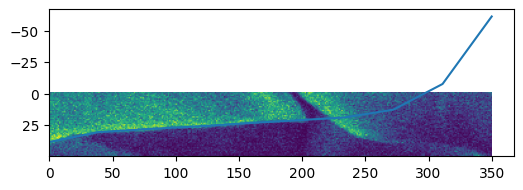

In [18]:
img_top_early=(crop(get_avg_img(50, 3)))[3]
img_top_late=(crop(get_avg_img(570, 3)))[3]

can_top_early = ski.feature.canny(denoise_tv_chambolle(img_top_early, weight = 0.2))
can_top_late = ski.feature.canny(denoise_tv_chambolle(img_top_late, weight = 0.2))

sobel_vert = ski.filters.sobel_h(can_top_late) > 0 

points = np.nonzero(sobel_vert)
points = [*zip(points[1], points[0])]

coe = RANSAC(points, 8, 200, 1, 50)

fig, axes = plt.subplots(1, 1, figsize=(6, 6))
axes.imshow(img_top_late)
plot_polynomial(axes, coe, imgsize = img_top_late.shape[1], alpha = 1)


In [19]:
def offset_top_left_coefficient(coeff):
    def get_y(x):
        y = 0
        i = 0
        for c in coeff:
            y += c * (x**i)
            i+=1
        return y
            
    return offset_equation_top_left(get_y)

def offset_top_right_coefficient(coeff):
    def get_y(x):
        y = 0
        i = 0
        for c in coeff:
            y += c * (x**i)
            i+=1
        return y
            
    return offset_equation_top_right(get_y)

def offset_bot_left_coefficient(coeff):
    def get_y(x):
        y = 0
        i = 0
        for c in coeff:
            y += c * (x**i)
            i+=1
        return y
            
    return offset_equation_bot_left(get_y)

def no_offset(coeff):
    def get_y(x):
        y = 0
        i = 0
        for c in coeff:
            y += c * (x**i)
            i+=1
        return y
            
    return get_y

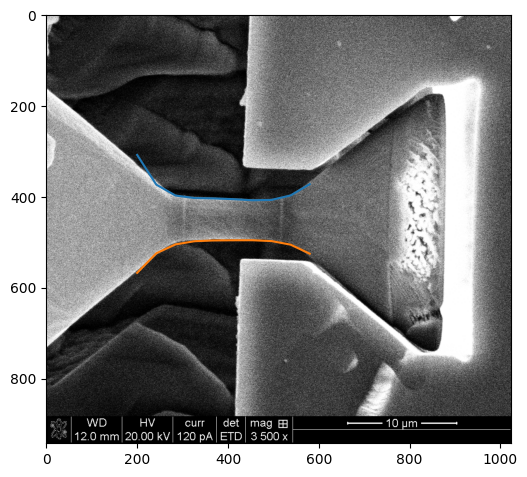

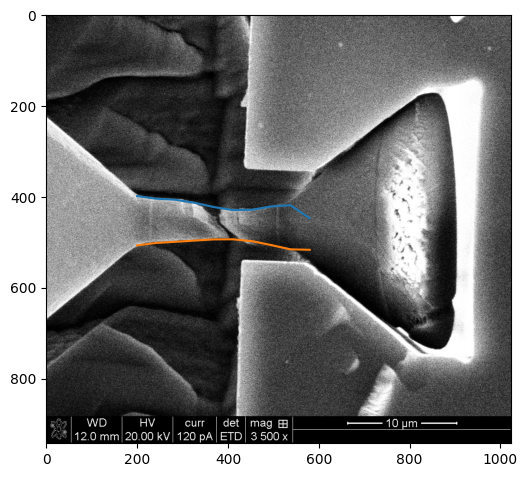

In [20]:
#Plot the four lines for the slides
#Also to deal with the offsets

img_early = (get_avg_img(10, 3))
img_late  = (get_avg_img(574, 3))

img_early_crops = crop(img_early)
img_late_crops = crop(img_late)

can_top_early = ski.feature.canny(denoise_tv_chambolle(img_early_crops[2], weight = 0.3))
can_bot_early = ski.feature.canny(denoise_tv_chambolle(img_early_crops[3], weight = 0.3))
can_top_late = ski.feature.canny(denoise_tv_chambolle(img_late_crops[2], weight = 0.3))
can_bot_late = ski.feature.canny(denoise_tv_chambolle(img_late_crops[3], weight = 0.3))


fig, axes = plt.subplots(1, 1, figsize=(6, 12))
axes.imshow(img_early, cmap=cm.gray)

points = np.nonzero(can_top_early)
points = [*zip(points[1], points[0])]

coe = RANSAC(points, 5, 200, 2, 10)
plot_function(axes, offset_top_left_coefficient(coe), left_x, right_x-170, alpha=1)

points = np.nonzero(can_bot_early)
points = [*zip(points[1], points[0])]

coe = RANSAC(points, 5, 300, 2, 10)
plot_function(axes, offset_bot_left_coefficient(coe), left_x, right_x-170, alpha=1)

fig, axes = plt.subplots(1, 1, figsize=(6, 12))
axes.imshow(img_late, cmap=cm.gray)

points = np.nonzero(can_top_late)
points = [*zip(points[1], points[0])]

coe = RANSAC(points, 5, 200, 2, 10)
plot_function(axes, offset_top_left_coefficient(coe), left_x, right_x-170, alpha=1)

points = np.nonzero(can_bot_late)
points = [*zip(points[1], points[0])]

coe = RANSAC(points, 5, 300, 2, 10)
plot_function(axes, offset_bot_left_coefficient(coe), left_x, right_x-170, alpha=1)
#plot_polynomial(axes, best_coeff, imgsize = 350, alpha = 1)

In [21]:
def add_figures_hori(can_img, img, ax, name='Original image'):

    ax[0].imshow(can_img, cmap=cm.gray)
    ax[0].set_title(name)
    ax[0].set_axis_off()

    ax[1].imshow(can_img, cmap=cm.gray)
    #ax[1].set_ylim((can_img.shape[0], 0))
    ax[1].set_axis_off()
    ax[1].set_title('Detected lines')

    for _, angle, dist in zip(*hough_line_peaks(h, theta, d, num_peaks=15)):
        (x0, y0) = dist * np.array([np.cos(angle), np.sin(angle)])
        ax[1].axline((x0, y0), slope=np.tan(angle + np.pi / 2))

    ax[2].imshow(img, cmap=cm.gray)
    ax[2].set_axis_off()
    for _, angle, dist in zip(*hough_line_peaks(h, theta, d, num_peaks=15)):
            (x0, y0) = dist * np.array([np.cos(angle), np.sin(angle)])
            ax[2].axline((x0, y0), slope=np.tan(angle + np.pi / 2))
            #print(x0, y0, np.tan(angle + np.pi / 2))

In [22]:
def generate_sanity(size, thresh = 40):
    def sanity(coe):
        x = np.linspace(0, size, 10)
        y = PolyCoefficients(x, coe)
        return not ((y > thresh).any())
    return sanity

#img should be a canny img
def find_polynomial(img, degree = 5, it = 50000):
    points = np.nonzero(img)
    points = [*zip(points[1], points[0])] #Flip cause images are wacky
    points = points
    print(len(points), img.shape)
    return randomized_hough_polynomial(points, degree, generate_sanity(img.shape[1]), num_iterations=it)


def PolyCoefficients(x, coeffs):

    #print(x)
    o = len(coeffs)
    y = 0
    for i in range(o):
        y += coeffs[i]*x**i

    #y = np.clip(y, 0, 40)    
    return y

def plot_polynomial(ax, coeffs, imgsize=250, alpha = 0.5):
    x = np.linspace(0, imgsize, 10)
    ax.plot(x, PolyCoefficients(x, coeffs), alpha = alpha)

def plot_function(ax, func, offset, imgsize=250, alpha = 0.5):
    x = np.linspace(offset, offset + imgsize, 10)
    ax.plot(x, func(x), alpha = alpha)

In [23]:
img_top_early=(crop(get_avg_img(50, 3)))[2]
img_top_late=(crop(get_avg_img(570, 3)))[2]

can_top_early = ski.feature.canny(denoise_tv_chambolle(img_top_early))
can_top_late = ski.feature.canny(denoise_tv_chambolle(img_top_late))

sobel_vert = ski.filters.sobel_h(can_top_early) > 0 
"""

fig, axes = plt.subplots(1, 2, figsize=(12, 12))
axes[0].imshow(sobel_vert, cmap=cm.gray)
axes[1].imshow(can_top_early)

#plt.subplotsfind_polynomial(1, 1, figsize=(12, 12))
#print((find_polynomial(can_top_early)[0]))
plot_polynomial(axes[0], (find_polynomial(can_top_early, degree = 2, it = 200)[0])[::-1], imgsize = can_top_early.shape[1])

#axes[0].imshow(can_top_early)

#fig, axes = plt.subplots(1, 1, figsize=(12, 12))
#plot_polynomial(axes, (find_polynomial(img_top_early)[0]))
#axes.hist(img_top_ear)
"""

'\n\nfig, axes = plt.subplots(1, 2, figsize=(12, 12))\naxes[0].imshow(sobel_vert, cmap=cm.gray)\naxes[1].imshow(can_top_early)\n\n#plt.subplotsfind_polynomial(1, 1, figsize=(12, 12))\n#print((find_polynomial(can_top_early)[0]))\nplot_polynomial(axes[0], (find_polynomial(can_top_early, degree = 2, it = 200)[0])[::-1], imgsize = can_top_early.shape[1])\n\n#axes[0].imshow(can_top_early)\n\n#fig, axes = plt.subplots(1, 1, figsize=(12, 12))\n#plot_polynomial(axes, (find_polynomial(img_top_early)[0]))\n#axes.hist(img_top_ear)\n'

In [24]:

"""
fig, axes = plt.subplots(4, 1, figsize=(8, 24))
points = np.nonzero(can_top_late)
axes[0].scatter(points[1], points[0])
axes[1].scatter(points[1], points[0])
axes[2].scatter(points[1], points[0])
axes[3].scatter(points[1], points[0])
#plot_polynomial(axes, (find_polynomial(can_top_early)[0]), imgsize = 300)
#handbuilt curve that we want
x = [75, 200, 300, 54, 330]
y = [10, 14, 11, 1, 1]
axes[0].scatter(x, y)
coe = np.polyfit(x, y, 5)
plot_polynomial(axes[0], coe[::-1], imgsize = can_top_early.shape[1])

x = np.linspace(0, can_top_early.shape[1], 10)
#print(PolyCoefficients(x, coe[::-1]))
#print(x)

points = [*zip(points[1], points[0])]

inliers = find_inliers(points, coe[::-1], 2)
#print(inliers.shape)
axes[1].scatter(inliers[:, :, 0], inliers[:, :, 1])

coe = np.polyfit(inliers[:, :, 0].flatten(), inliers[:, :, 1].flatten(), 5)
plot_polynomial(axes[1], coe[::-1], imgsize = can_top_early.shape[1])
inliers = find_inliers(points, coe[::-1], 5)
axes.scatter(inliers[:, :, 0], inliers[:, :, 1])
coe = np.polyfit(inliers[:, :, 0].flatten(), inliers[:, :, 1].flatten(), 2)
plot_polynomial(axes, coe[::-1], imgsize = can_top_early.shape[1])
#points, min_samples, max_it, max_error, data_threshold
coe = RANSAC(points, 5, 20, 2, 30)
print(coe)
plot_polynomial(axes[2], coe[::-1], imgsize = can_top_early.shape[1])
"""


'\nfig, axes = plt.subplots(4, 1, figsize=(8, 24))\npoints = np.nonzero(can_top_late)\naxes[0].scatter(points[1], points[0])\naxes[1].scatter(points[1], points[0])\naxes[2].scatter(points[1], points[0])\naxes[3].scatter(points[1], points[0])\n#plot_polynomial(axes, (find_polynomial(can_top_early)[0]), imgsize = 300)\n#handbuilt curve that we want\nx = [75, 200, 300, 54, 330]\ny = [10, 14, 11, 1, 1]\naxes[0].scatter(x, y)\ncoe = np.polyfit(x, y, 5)\nplot_polynomial(axes[0], coe[::-1], imgsize = can_top_early.shape[1])\n\nx = np.linspace(0, can_top_early.shape[1], 10)\n#print(PolyCoefficients(x, coe[::-1]))\n#print(x)\n\npoints = [*zip(points[1], points[0])]\n\ninliers = find_inliers(points, coe[::-1], 2)\n#print(inliers.shape)\naxes[1].scatter(inliers[:, :, 0], inliers[:, :, 1])\n\ncoe = np.polyfit(inliers[:, :, 0].flatten(), inliers[:, :, 1].flatten(), 5)\nplot_polynomial(axes[1], coe[::-1], imgsize = can_top_early.shape[1])\ninliers = find_inliers(points, coe[::-1], 5)\naxes.scatter(i

In [25]:
def average_out_lines_param(img, thresh = 10):
    tested_angles = np.linspace(0, np.pi / 64, 360, endpoint=False)
    h, theta, d = hough_line(img, theta=tested_angles)

    existing_lines = []

    for _, angle, dist in zip(*hough_line_peaks(h, theta, d, num_peaks=15)):
        (x0, y0) = dist * np.array([np.cos(angle), np.sin(angle)])
        averaged = False

        for line in existing_lines:
            if (abs(line[0]-x0) < thresh):
                line[0] = (line[3] * line[0] + x0)/(line[3]+1)
                line[1] = line[1] + y0
                line[2] = line[2] + np.tan(angle + np.pi / 2)
                line[3]+=1
                averaged = True
                break
        if not averaged:
            existing_lines.insert(0, [x0, y0, np.tan(angle + np.pi / 2), 1])

    for line in existing_lines:
        line[1]/=line[3]
        line[2]/=line[3]

    existing_lines.sort(key=(lambda a : a[3]), reverse=True)

    line[0] = line[1] - line[2] * line[0]
    line[1] = line[2]

    #0 is y0, 1 is theta

    return existing_lines[0][:2]

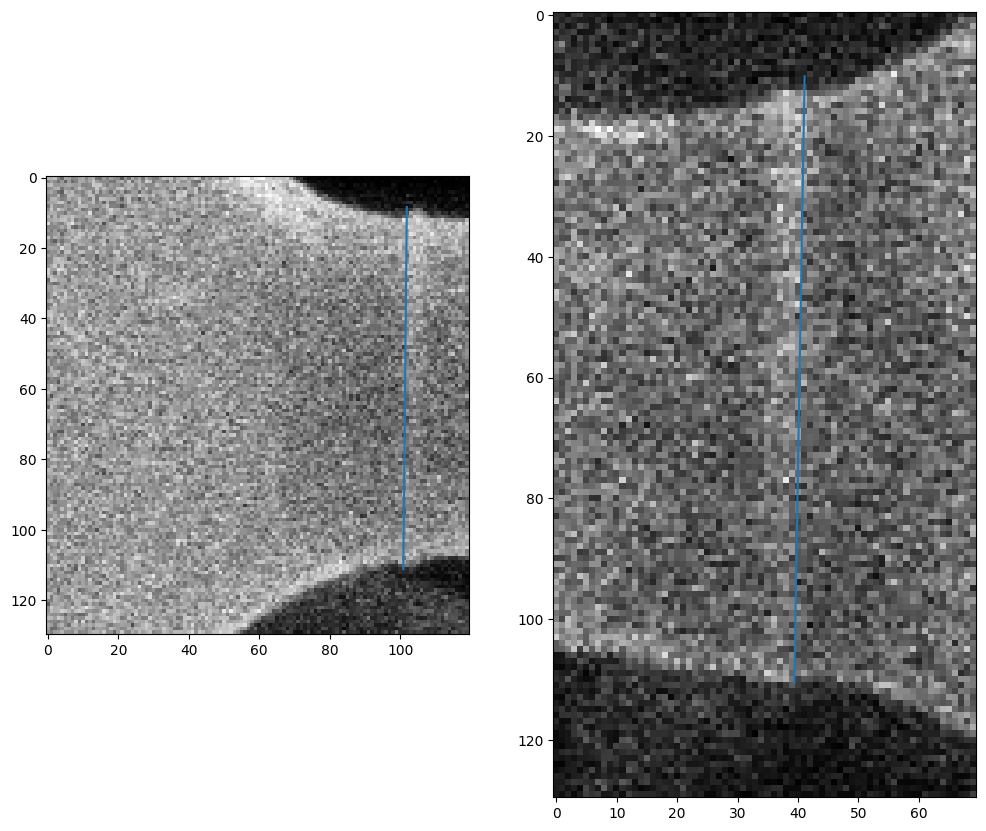

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 12))

img_early = (get_avg_img(10, 3))
img_late  = (get_avg_img(574, 3))

img_early_crops = crop(img_early)
img_late_crops = crop(img_late)

can_left_early = ski.feature.canny(denoise_tv_chambolle(img_early_crops[0]))
can_right_early = ski.feature.canny(denoise_tv_chambolle(img_early_crops[1]))

axes[0].imshow(img_early_crops[0], cmap = cm.gray)
axes[1].imshow(img_early_crops[1], cmap = cm.gray)

coeff = average_out_lines_param(can_left_early, 20)
plot_function(axes[0], no_offset(coeff), 100.9, 1, alpha =1)

coeff = average_out_lines_param(can_right_early, 20)
plot_function(axes[1], no_offset(coeff), 39.4, 1.7, alpha =1)

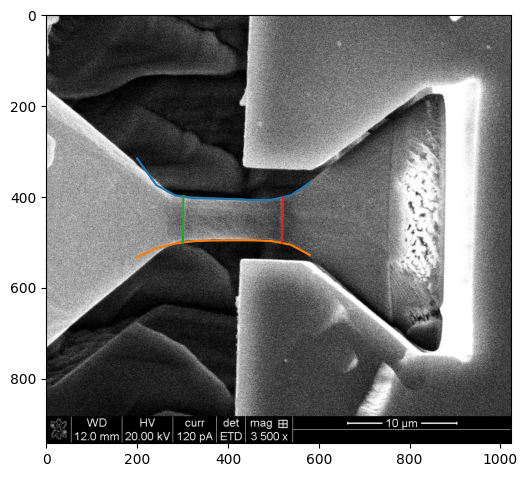

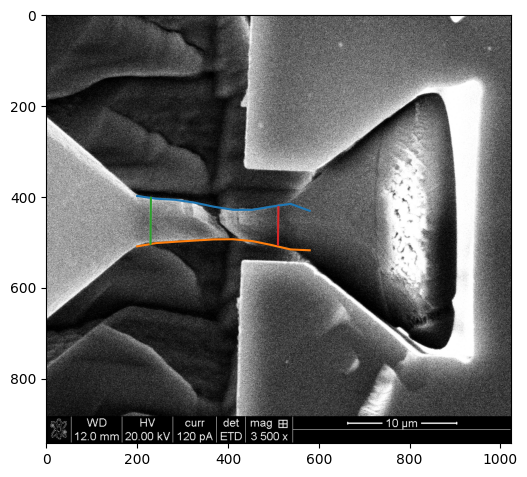

In [27]:
#Plot the four lines for the slides
#Also to deal with the offsets

img_early = (get_avg_img(10, 3))
img_late  = (get_avg_img(574, 3))

img_early_crops = crop(img_early)
img_late_crops = crop(img_late)

can_top_early = ski.feature.canny(denoise_tv_chambolle(img_early_crops[2], weight = 0.3))
can_bot_early = ski.feature.canny(denoise_tv_chambolle(img_early_crops[3], weight = 0.3))
can_top_late = ski.feature.canny(denoise_tv_chambolle(img_late_crops[2], weight = 0.3))
can_bot_late = ski.feature.canny(denoise_tv_chambolle(img_late_crops[3], weight = 0.3))


fig, axes = plt.subplots(1, 1, figsize=(6, 12))
axes.imshow(img_early, cmap=cm.gray)

points = np.nonzero(can_top_early)
points = [*zip(points[1], points[0])]

coe = RANSAC(points, 5, 200, 2, 10)
plot_function(axes, offset_top_left_coefficient(coe), left_x, right_x-170, alpha=1)

points = np.nonzero(can_bot_early)
points = [*zip(points[1], points[0])]

coe = RANSAC(points, 5, 300, 2, 10)
plot_function(axes, offset_bot_left_coefficient(coe), left_x, right_x-170, alpha=1)

can_left_early = ski.feature.canny(denoise_tv_chambolle(img_early_crops[0]))
can_right_early = ski.feature.canny(denoise_tv_chambolle(img_early_crops[1]))
coeff = average_out_lines_param(can_left_early, 20)
plot_function(axes, offset_top_left_coefficient(coeff), left_x + 100.9, 1, alpha =1)
coeff = average_out_lines_param(can_right_early, 20)
plot_function(axes, offset_top_right_coefficient(coeff), (left_x + right_offset) + 39.4, 1.7, alpha =1)

fig, axes = plt.subplots(1, 1, figsize=(6, 12))
axes.imshow(img_late, cmap=cm.gray)

points = np.nonzero(can_top_late)
points = [*zip(points[1], points[0])]

coe = RANSAC(points, 5, 200, 2, 10)
plot_function(axes, offset_top_left_coefficient(coe), left_x, right_x-170, alpha=1)

points = np.nonzero(can_bot_late)
points = [*zip(points[1], points[0])]

coe = RANSAC(points, 5, 300, 2, 10)
plot_function(axes, offset_bot_left_coefficient(coe), left_x, right_x-170, alpha=1)

can_left_late = ski.feature.canny(denoise_tv_chambolle(img_late_crops[0]))
can_right_late = ski.feature.canny(denoise_tv_chambolle(img_late_crops[1]))
coeff = average_out_lines_param(can_left_late, 20)
plot_function(axes, offset_top_left_coefficient(coeff), left_x + 29.4, .9, alpha =1)
coeff = average_out_lines_param(can_right_late, 20)
plot_function(axes, offset_top_right_coefficient(coeff), (left_x + right_offset) + 30, 1.1, alpha =1)
#plot_polynomial(axes, best_coeff, imgsize = 350, alpha = 1)

In [28]:
#Now calculate the intersections and graph

In [29]:
def find_intersection(funcA, funcB, err = 0.01):
    # Finds intersection of two function given that there is only one intersection.
    # Very scuff

    ans = 50
    def score(x):
        return funcA(x) - funcB(x)

    def slope(x):
        return score(x+1) - score(x-1)

    while (abs(score(ans)) > err):
        ans -= score(ans) / slope(ans)

    return (ans, funcA(ans))
    
def find_intersections(left, right, top, bot):
    return find_intersection(left, top), find_intersection(left, bot), find_intersection(right, top), find_intersection(right, bot)

def plot_intersections(axes, points):
    #points are top left, bot left, top right, bot left
    axes.plot((points[1][0], points[0][0]), (points[1][1], points[0][1]), color ="white")
    axes.plot((points[3][0], points[2][0]), (points[3][1], points[2][1]), color ="white")

In [30]:
def a(x):
    return x

def b(x):
    return x*x - 6

find_intersection(a, b)

(3.001643265347174, 3.001643265347174)

In [31]:
def can_tv_h(img):
    return ski.feature.canny(denoise_tv_chambolle(img, weight = 0.3))

def can_tv_v(img):
    return ski.feature.canny(denoise_tv_chambolle(img, weight = 0.07))

def find_poly(can_img):
    points = np.nonzero(can_img)
    points = [*zip(points[1], points[0])]
    return RANSAC(points, 5, 300, 2, 10)
    
def find_line(img):
    return average_out_lines_param(img, 20)

In [32]:
img  = (get_avg_img(99, 3))
img_crops = crop(img)

can_top = [can_tv_v(img_crops[0]), can_tv_v(img_crops[1]), can_tv_h(img_crops[2]), can_tv_h(img_crops[3])]
#fig, axes = plt.subplots(4,1)
#for i in range(4):
#    axes[i].imshow(can_top[i])

unaligned_coeff = [find_line(can_top[0]), find_line(can_top[1]), find_poly(can_top[2]), find_poly(can_top[3])]
aligned_func    = [offset_top_left_coefficient(unaligned_coeff[0]), offset_top_right_coefficient(unaligned_coeff[1]), offset_top_left_coefficient(unaligned_coeff[2]), offset_bot_left_coefficient(unaligned_coeff[3])]

inter  = find_intersections(*aligned_func)

#fig, axes = plt.subplots(1,1)
#axes.imshow(img, cmap = cm.gray)
#plot_function(axes, offset_top_left_coefficient(unaligned_coeff[2]), left_x, right_x-170, alpha=1)

#fig, axes = plt.subplots(1,1)

#axes.imshow(img, cmap = cm.gray)
#plot_intersections(axes, inter)

In [33]:
#Anti hysterisis, or if it deviates too much from the previous value, try finding the lines again until it works


In [34]:
from tqdm import tqdm

for i in tqdm(range(1, 609), ascii=True):
    img  = (get_avg_img(i, 3))
    img_crops = crop(img)

    can_top = [can_tv_v(img_crops[0]), can_tv_v(img_crops[1]), can_tv_h(img_crops[2]), can_tv_h(img_crops[3])]

    unaligned_coeff = [find_line(can_top[0]), find_line(can_top[1]), find_poly(can_top[2]), find_poly(can_top[3])]
    aligned_func    = [offset_top_left_coefficient(unaligned_coeff[0]), offset_top_right_coefficient(unaligned_coeff[1]), offset_top_left_coefficient(unaligned_coeff[2]), offset_bot_left_coefficient(unaligned_coeff[3])]

    inter  = find_intersections(*aligned_func)

    img = get_file(i)
    fig = plt.figure(figsize=(10.24, 9.43))
    ax = fig.add_axes([0, 0, 1, 1])
    ax.imshow(img, cmap=cm.gray)
    ax.set_ylim((img.shape[0], 0))
    ax.set_axis_off()

    plot_intersections(ax, inter)

    fig.savefig(f"imgs2/out/{i}.jpg", bbox_inches='tight', pad_inches=0)
    plt.close()

100%|##########| 608/608 [13:46<00:00,  1.36s/it]


In [ ]:
from tqdm import tqdm

for i in tqdm(range(1, 609), ascii=True):
    img  = (get_avg_img(i, 3))

    fig = plt.figure(figsize=(10.24, 9.43))
    ax = fig.add_axes([0, 0, 1, 1])
    ax.imshow(img, cmap=cm.gray)
    ax.set_ylim((img.shape[0], 0))
    ax.set_axis_off()

    fig.savefig(f"imgs2/stacked/{i}.tiff", bbox_inches='tight', pad_inches=0)
    plt.close()

  0%|          | 0/78 [00:00<?, ?it/s]

100%|##########| 78/78 [00:43<00:00,  1.79it/s]
